
# Handwritten Digit Recognition Using Convolutional Neural Networks

## A Comparative Study of LeCun (1989) and Chollet (2021)

**Module:** Computer Vision  
**Dataset:** MNIST Handwritten Digits  
**Models:** LeCun-inspired CNN and Chollet CNN  
**Framework:** TensorFlow / Keras

---

## 1. Introduction

Handwritten digit recognition is a fundamental image classification problem in computer vision. The objective is to develop a computational model capable of identifying handwritten numerical digits from images and assigning each image to one of ten classes, representing the digits zero through nine.

Convolutional Neural Networks (CNNs) have become particularly effective for image recognition because they can automatically learn spatial features from image data. Unlike traditional machine learning approaches that often depend on manually engineered features, CNNs use convolutional filters to identify patterns such as edges, curves and more complex visual structures.

LeCun et al. (1989), in their work *Backpropagation Applied to Handwritten Zip Code Recognition*, demonstrated the effectiveness of convolutional neural networks for recognising handwritten digits. Their approach introduced important architectural principles, including local receptive fields, shared weights and subsampling.

This practical investigates these principles by implementing a LeCun-inspired convolutional neural network using modern TensorFlow/Keras functionality. Its performance is compared with the conventional MNIST CNN implementation presented by François Chollet (2021).

The experiment uses the MNIST dataset, which contains grayscale images of handwritten digits. Both networks are trained and evaluated using a consistent experimental protocol to investigate their classification performance and computational requirements.

### 1.1 Aim

The aim of this practical is to implement and evaluate a historical LeCun-inspired convolutional neural network for handwritten digit recognition and compare its performance with the Chollet (2021) Keras implementation.

### 1.2 Objectives

The objectives are to:

1. Describe and explore the MNIST handwritten digit dataset.
2. Implement a CNN based on the architectural principles of LeCun et al. (1989).
3. Explain and justify the modifications required to adapt the historical architecture to modern Keras and the MNIST dataset.
4. Implement the Chollet (2021) CNN as a comparison baseline.
5. Compare the architectures, preprocessing methods, training configurations and trainable parameters.
6. Train and evaluate both networks using multiple independent runs.
7. Compare test loss, test accuracy and training duration.
8. Analyse classification errors using confusion matrices and misclassified examples.

### 1.3 Research question

How does a LeCun-inspired convolutional neural network compare with the Chollet (2021) CNN implementation in recognising handwritten digits from the MNIST dataset?

### 1.4 References

- LeCun, Y., Boser, B., Denker, J. S., Henderson, D., Howard, R. E., Hubbard, W. and Jackel, L. D. (1989). Backpropagation Applied to Handwritten Zip Code Recognition. *Neural Computation*, 1(4), 541–551.
- Chollet, F. (2021). *Deep Learning with Python*. 2nd ed. Manning Publications.

## 2. MNIST Dataset

The Modified National Institute of Standards and Technology (MNIST) dataset is a widely used benchmark for handwritten digit classification. It consists of 70,000 grayscale images representing the digits zero through nine.

Each image has a resolution of 28 × 28 pixels, with pixel intensity values ranging from 0 to 255. The dataset is divided into 60,000 training images and 10,000 test images.

The classification task involves assigning each image to one of ten possible classes. The dataset provides a consistent benchmark for evaluating image classification models and allows the performance of different CNN architectures to be compared.

### 2.1 Dataset characteristics

The following characteristics are relevant to this practical:

- **Total images:** 70,000
- **Training images:** 60,000
- **Test images:** 10,000
- **Image dimensions:** 28 × 28 pixels
- **Colour channels:** 1 (grayscale)
- **Number of classes:** 10
- **Class labels:** Digits 0–9

In the following section, the dataset will be loaded and explored to verify its dimensions, examine the distribution of digit classes and visualise representative handwritten digit images.

In [1]:
"""Load the MNIST dataset and inspect its structure."""

import json
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from mnist_lecun_cnn.analysis import (
    aggregate_histories,
    aggregate_run_metrics,
    load_analysis_inputs,
    plot_learning_curve,
)
from mnist_lecun_cnn.data import create_train_validation_split
from mnist_lecun_cnn.preprocessing import (
    preprocess_chollet_images,
    preprocess_lecun_images,
    encode_chollet_targets,
    encode_lecun_targets,
)
from mnist_lecun_cnn.experiment import run_experiments
from mnist_lecun_cnn.models.chollet import build_chollet_model
from mnist_lecun_cnn.models.lecun import build_lecun_model

# Load the MNIST dataset from Keras.
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

# Display dataset dimensions.
print("MNIST Dataset Overview")
print("-" * 40)
print(f"Training images: {x_train.shape}")
print(f"Training labels: {y_train.shape}")
print(f"Test images:     {x_test.shape}")
print(f"Test labels:     {y_test.shape}")

# Display image properties.
print("\nImage Properties")
print("-" * 40)
print(f"Image dimensions:  {x_train.shape[1]} × {x_train.shape[2]}")
print(f"Pixel data type:   {x_train.dtype}")
print(f"Minimum pixel:     {x_train.min()}")
print(f"Maximum pixel:     {x_train.max()}")
print(f"Number of classes: {len(np.unique(y_train))}")

MNIST Dataset Overview
----------------------------------------
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images:     (10000, 28, 28)
Test labels:     (10000,)

Image Properties
----------------------------------------
Image dimensions:  28 × 28
Pixel data type:   uint8
Minimum pixel:     0
Maximum pixel:     255
Number of classes: 10


Digit Class Distribution
----------------------------------------
Digit     Training       Test           
0         5923           980            
1         6742           1135           
2         5958           1032           
3         6131           1010           
4         5842           982            
5         5421           892            
6         5918           958            
7         6265           1028           
8         5851           974            
9         5949           1009           


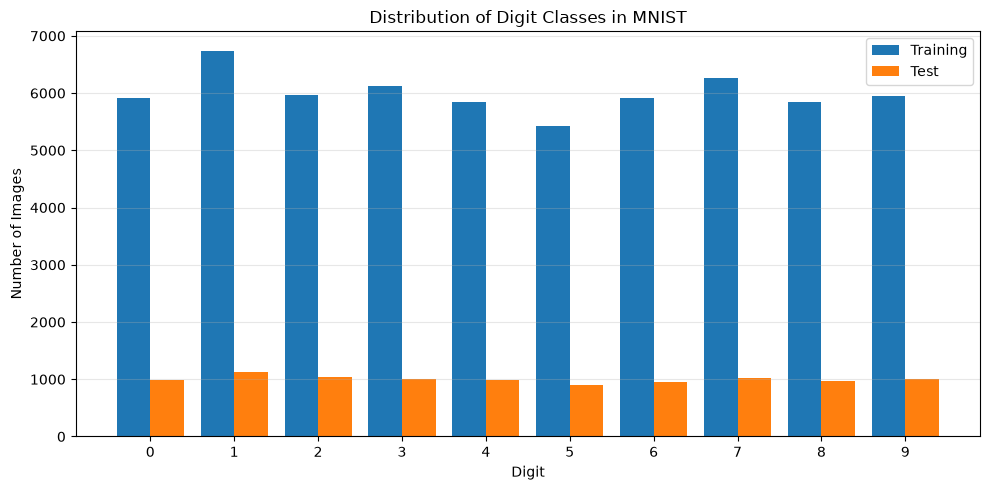

In [2]:
"""Examine the distribution of digit classes in MNIST."""

# Count occurrences of each digit.
train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

# Display class distribution.
print("Digit Class Distribution")
print("-" * 40)
print(f"{'Digit':<10}{'Training':<15}{'Test':<15}")

for digit in range(10):
    print(f"{digit:<10}{train_counts[digit]:<15}{test_counts[digit]:<15}")

# Visualise the training and test distributions.
digits = np.arange(10)
width = 0.4

plt.figure(figsize=(10, 5))
plt.bar(digits - width / 2, train_counts, width, label="Training")
plt.bar(digits + width / 2, test_counts, width, label="Test")

plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.title("Distribution of Digit Classes in MNIST")
plt.xticks(digits)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 2.2 Interpretation of Class Distribution

The class distribution shows that all ten digit classes are represented in both the training and test datasets. However, the number of images is not exactly equal across the classes.

In the training dataset, digit 1 has the highest representation, with 6,742 images, while digit 5 has the lowest representation, with 5,421 images. A similar pattern is observed in the test dataset, where digit 1 has 1,135 images and digit 5 has 892 images.

Despite these differences, the distribution is reasonably balanced, as no individual class overwhelmingly dominates the dataset. The training and test distributions also show similar patterns, which provides a consistent basis for model training and evaluation.

The class distribution is important because substantial differences in the number of examples per class could influence a model's learning behaviour and classification performance. Although MNIST is not perfectly balanced, the observed distribution does not indicate a severe class imbalance.

Therefore, all ten classes can be retained for the experiments without requiring additional class-balancing techniques.

### 2.3 Visual Inspection of Handwritten Digits

A visual inspection of sample images helps illustrate the characteristics of the MNIST dataset and the variation in handwriting across the ten digit classes.

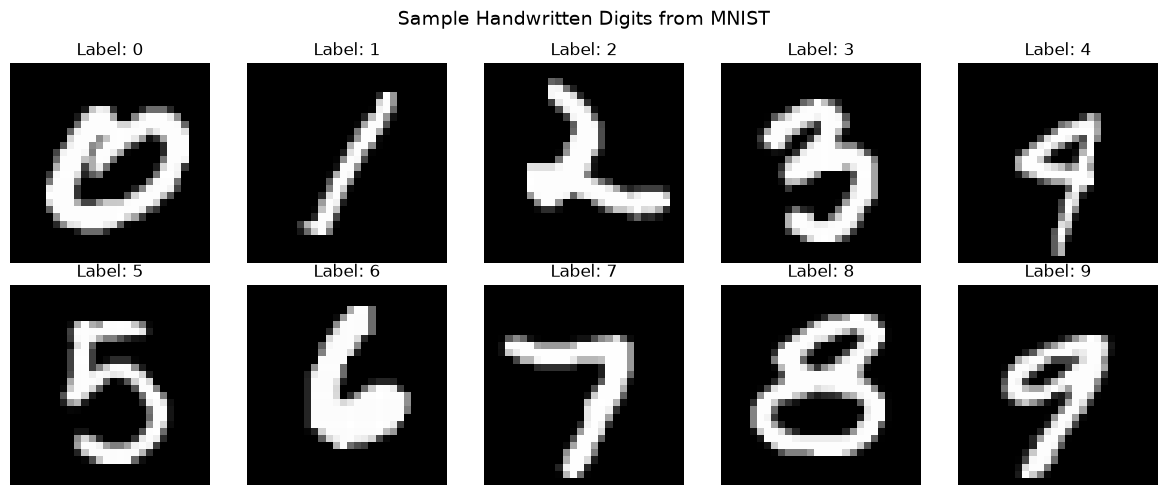

In [3]:
"""Visualise sample handwritten digits from the MNIST training dataset."""

# Select one reproducible random example from each digit class.
rng = np.random.default_rng(42)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for digit, ax in enumerate(axes.flat):
    # Find all training images belonging to the current digit.
    digit_indices = np.where(y_train == digit)[0]

    # Select one image at random.
    image_index = rng.choice(digit_indices)

    # Display the image and its label.
    ax.imshow(x_train[image_index], cmap="gray")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")

plt.suptitle("Sample Handwritten Digits from MNIST", fontsize=14)
plt.tight_layout()
plt.show()

### 2.4 Interpretation of Visual Inspection

The sample images demonstrate that the MNIST dataset contains handwritten digits with varying shapes, sizes, proportions and writing styles. Although each image represents one of the ten digit classes, the appearance of the digits is not completely uniform.

For example, the digit 1 is represented by a narrow, slightly slanted stroke, while the digit 8 contains two distinct loops. Other digits, such as 2, 3 and 5, demonstrate different combinations of curved and angular strokes.

The images also show variation in stroke thickness, orientation and overall proportions. These differences illustrate why handwritten digit recognition is a classification challenge: a model must learn the important features that distinguish each digit despite variations in individual handwriting styles.

This visual inspection highlights the importance of convolutional neural networks. Their convolutional filters can learn local image features, such as edges, curves and stroke patterns, which can be combined to recognise more complex digit structures.

The selected images provide representative examples of the ten classes, although they do not capture the full variation present in the dataset.

### 3.1 Training and Validation Split

The original MNIST training dataset is divided into training and validation subsets using stratified sampling. A validation set of 6,000 images is selected, leaving 54,000 images for training.

Stratification ensures that the relative representation of the ten digit classes is maintained across both subsets. A random seed of 42 is used to make the split reproducible.

The official MNIST test dataset remains untouched and is reserved for the final model evaluation.

In [4]:
"""Create a reproducible stratified training/validation split."""

# Generate stratified indices using the project's data pipeline.
split = create_train_validation_split(
    y_train,
    validation_size=6000,
    random_seed=42,
)

# Construct the training and validation subsets.
x_train_split = x_train[split.train_indices]
y_train_split = y_train[split.train_indices]

x_val = x_train[split.validation_indices]
y_val = y_train[split.validation_indices]

# Display the resulting dataset dimensions.
print("Dataset Split")
print("-" * 45)
print(f"Training images:   {x_train_split.shape}")
print(f"Training labels:   {y_train_split.shape}")
print(f"Validation images: {x_val.shape}")
print(f"Validation labels: {y_val.shape}")
print(f"Test images:       {x_test.shape}")
print(f"Test labels:       {y_test.shape}")

Dataset Split
---------------------------------------------
Training images:   (54000, 28, 28)
Training labels:   (54000,)
Validation images: (6000, 28, 28)
Validation labels: (6000,)
Test images:       (10000, 28, 28)
Test labels:       (10000,)


### 3.2 Interpretation of Dataset Split

The dataset was successfully divided into 54,000 training images and 6,000 validation images. The original 10,000-image test dataset was retained separately.

The training subset provides the examples used to update the network weights during learning. The validation subset allows the models' performance to be monitored on data that is not used for weight updates. This helps assess how well each model generalises beyond its training examples.

The stratified splitting procedure maintains the class distribution across the training and validation subsets. Using a fixed random seed of 42 also ensures that the same split can be reproduced in subsequent experiments.

Keeping the official test dataset separate prevents it from influencing model training and validation. It will therefore provide an independent basis for comparing the final performance of the two CNN architectures.

### 3.3 Model-Specific Image Preprocessing

Different preprocessing strategies are applied to the two CNN architectures to reflect their respective design approaches.

The LeCun-inspired model uses foreground cropping, aspect-ratio-preserving resizing and centring to produce a standardised digit representation. Its pixel values are normalised to the range [-1, 1].

The Chollet model retains the original MNIST image dimensions and applies normalisation to the range [0, 1], without additional geometric transformations.

These differences are maintained throughout the experiments so that each architecture is evaluated using its intended input representation.

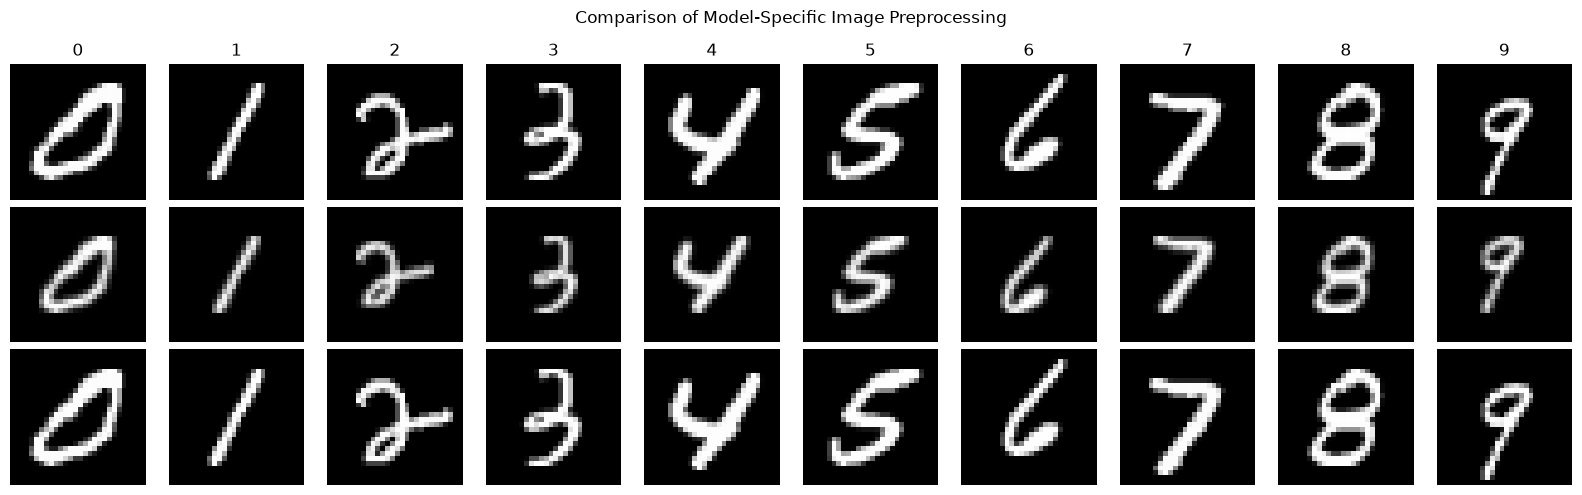

Preprocessing Output
---------------------------------------------
LeCun shape: (10, 28, 28, 1)
LeCun range: [-1.00, 1.00]
Chollet shape: (10, 28, 28, 1)
Chollet range: [0.00, 1.00]


In [5]:
"""Compare the image preprocessing pipelines of bot CNN models."""

# Select one training example from each digit class.
sample_indices = [
    np.where(y_train_split == digit)[0][0]
    for digit in range(10)
]

sample_images = x_train_split[sample_indices]
sample_labels = y_train_split[sample_indices]

# Apply both preprocessing pipelines.
lecun_samples = preprocess_lecun_images(sample_images)
chollet_samples = preprocess_chollet_images(sample_images)

# Display the original and preprocessed images.
fig, axes = plt.subplots(3, 10, figsize=(16, 5))

for i in range(10):
    axes[0, i].imshow(sample_images[i], cmap="gray")
    axes[0, i].set_title(str(sample_labels[i]))
    axes[0, i].axis("off")

    axes[1, i].imshow(
        lecun_samples[i, :, :, 0],
        cmap="gray",
        vmin=-1,
        vmax=1,
    )
    axes[1, i].axis("off")

    axes[2, i].imshow(
        chollet_samples[i, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("LeCun", fontsize=10)
axes[2, 0].set_ylabel("Chollet", fontsize=10)

plt.suptitle("Comparison of Model-Specific Image Preprocessing")
plt.tight_layout()
plt.show()

# Display the resulting array properties.
print("Preprocessing Output")
print("-" * 45)
print(f"LeCun shape: {lecun_samples.shape}")
print(f"LeCun range: [{lecun_samples.min():.2f}, {lecun_samples.max():.2f}]")
print(f"Chollet shape: {chollet_samples.shape}")
print(
    "Chollet range: "
    f"[{chollet_samples.min():.2f}, {chollet_samples.max():.2f}]"
)

### 3.4 Interpretation of Image Preprocessing

The visual comparison demonstrates the differences between the two preprocessing pipelines.

The LeCun-inspired preprocessing procedure crops each digit to its non-zero foreground bounding box, resizes it while preserving its aspect ratio and centres it within a 28 × 28 image. This produces a more standardised representation of the handwritten digits while retaining their general shapes.

The Chollet preprocessing pipeline retains the original MNIST image geometry. It only converts the pixel values to floating-point numbers and normalises them to the range [0, 1].

Both pipelines produce images with dimensions of 28 × 28 pixels and one channel, giving an output shape of (10, 28, 28, 1) for the ten selected examples. However, their pixel-value ranges differ: [-1, 1] for LeCun and [0, 1] for Chollet.

These differences reflect the design choices of the respective architectures. The LeCun-inspired approach emphasises standardising digit size and position, while the Chollet approach preserves the original image representation.

The preprocessing procedures are therefore important experimental considerations because each network learns from a different representation of the same handwritten digit dataset.

### 3.5 Target Encoding

The class labels are encoded differently for the two CNN architectures.

The LeCun-inspired model uses bipolar target encoding, where the correct class is represented by +1 and all other classes by -1. This is consistent with its use of hyperbolic tangent activation functions and mean squared error loss.

The Chollet model uses one-hot encoding, where the correct class is represented by 1 and all other classes by 0. This is used with its softmax output layer and categorical cross-entropy loss.

Both approaches represent the same ten digit classes, but their numerical target representations differ.

In [6]:
"""Compare the target encoding methods used by both CNN models."""

# Select five examples from the training labels.
sample_labels = y_train_split[:5]

# Encode the labels using both approaches.
lecun_targets = encode_lecun_targets(sample_labels)
chollet_targets = encode_chollet_targets(sample_labels)

# Display the original labels and encoded targets.
print("Original Labels:")
print(sample_labels)

print("\nLeCun Bipolar Targets:")
print(lecun_targets)

print("\nChollet One-Hot Targets:")
print(chollet_targets)

Original Labels:
[2 1 5 1 8]

LeCun Bipolar Targets:
[[-1. -1.  1. -1. -1. -1. -1. -1. -1. -1.]
 [-1.  1. -1. -1. -1. -1. -1. -1. -1. -1.]
 [-1. -1. -1. -1. -1.  1. -1. -1. -1. -1.]
 [-1.  1. -1. -1. -1. -1. -1. -1. -1. -1.]
 [-1. -1. -1. -1. -1. -1. -1. -1.  1. -1.]]

Chollet One-Hot Targets:
[[0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]]


### 3.6 Interpretation of Target Encoding

The output confirms that both target encoding methods correctly represent the original digit labels.

For the selected labels [2, 1, 5, 1, 8], each encoding produces a vector containing ten elements, corresponding to the ten possible digit classes.

In the LeCun-inspired encoding, the correct class is assigned a value of +1, while all remaining classes receive -1. This produces bipolar target vectors that are compatible with the model's tanh output activation and mean squared error loss function.

In the Chollet encoding, the correct class receives a value of 1, while all remaining classes receive 0. This produces one-hot target vectors that are compatible with the softmax output activation and categorical cross-entropy loss function.

Although the numerical representations differ, both encoding methods identify the same correct digit class. Each model therefore receives target labels appropriate to its output layer and loss function.

#### 4.1.1 LeCUn-inspired Model Summary

The model summary provides the output dimensions and trainable parameter count for each layer. This allows the implemented architecture to be checked against its intended design.

In [7]:
"""Build and inspect the LeCun-inspired CNN."""

# Build the LeCun-inspired network.
lecun_model = build_lecun_model()

# Display the architecture.
lecun_model.summary()

# Display the total number o trainable parameters.
lecun_parameters = lecun_model.count_params()

print(f"\nTotla trainable parameters: {lecun_parameters:,}")

Model: "lecun_inspired_cnn"

┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━┓
┃               ┃              ┃  Param ┃              ┃
┃ Layer (type)  ┃ Output Shape ┃      # ┃ Connected to ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━┩
│ image         │ (None, 28,   │      0 │ -            │
│ (InputLayer)  │ 28, 1)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h1_convoluti… │ (None, 24,   │    104 │ image[0][0]  │
│ (Conv2D)      │ 24, 4)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h2_average_p… │ (None, 12,   │      0 │ h1_convolut… │
│ (AveragePool… │ 12, 4)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h2_trainable… │ (None, 12,   │      8 │ h2_average_… │
│ (PerChannelA… │ 12, 4)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_1_input_s… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 1)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_2_input_s… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 2)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_3_input_s… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 2)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_4_input_s… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 1)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_5_input_s… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 2)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_6_input_s… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 2)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_7_input_s… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 1)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_8_input_s… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 2)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_9_input_s… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 2)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_10_input_… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 1)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_11_input_… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 2)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_12_input_… │ (None, 12,   │      0 │ h2_trainabl… │
│ (ChannelSele… │ 12, 2)       │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_1_convolu… │ (None, 8, 8, │     26 │ h3_1_input_… │
│ (Conv2D)      │ 1)           │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_2_convolu… │ (None, 8, 8, │     51 │ h3_2_input_… │
│ (Conv2D)      │ 1)           │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_3_convolu… │ (None, 8, 8, │     51 │ h3_3_input_… │
│ (Conv2D)      │ 1)           │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_4_convolu… │ (None, 8, 8, │     26 │ h3_4_input_… │
│ (Conv2D)      │ 1)           │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_5_convolu… │ (None, 8, 8, │     51 │ h3_5_input_… │
│ (Conv2D)      │ 1)           │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_6_convolu… │ (None, 8, 8, │     51 │ h3_6_input_… │
│ (Conv2D)      │ 1)           │        │              │
├───────────────┼──────────────┼────────┼──────────────┤
│ h3_7_con

 Total params: 2,578 (10.07 KB)

 Trainable params: 2,578 (10.07 KB)

 Non-trainable params: 0 (0.00 B)


Totla trainable parameters: 2,578


#### 4.1.2 Interpretation of the LeCun Model Summary

The model summary confirms that the LeCun-inspired CNN follows the intended architecture and contains 2,578 trainable parameters.

The first convolutional layer (H1) produces four feature maps using 5 × 5 filters. The resulting feature maps are reduced through average pooling in H2, which produces four 12 × 12 feature maps. Trainable scaling and bias parameters are applied to each feature map before the tanh activation.

The H3 layer produces twelve feature maps using 5 × 5 convolutions. Unlike a fully connected convolutional arrangement, each H3 feature map receives input from only one or two selected H2 feature maps. This restricted connectivity reduces the number of trainable parameters while retaining the ability to extract different spatial features.

The H4 layer applies another average pooling operation, reducing the feature maps to dimensions of 4 × 4 × 12. These feature maps are flattened into 192 features and passed to a fully connected output layer containing ten neurons, representing the ten digit classes.

The network has 2,578 trainable parameters, all of which are trainable, with no non-trainable parameters. This relatively small parameter count reflects the use of a compact architecture with restricted feature-map connectivity.

The output layer uses tanh activation, which produces values compatible with the bipolar target encoding and mean squared error loss used during training.

#### 4.2.1 Chollet Model Summary

The model summary provides the output dimensions and trainable parameter count for each layer. This allows the implemented Chollet CNN to be checked against the architecture described by Chollet (2021).

In [8]:
"""Build and inspect the Chollet CNN."""

# Build the Chollet CNN.
chollet_model = build_chollet_model()

# Display the architecture.
chollet_model.summary()

# Display the total number of trainable parameters.
chollet_parameters = chollet_model.count_params()

print(f"\nTotal trainable parameters: {chollet_parameters:,}")

Model: "chollet_mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Layer (type)           ┃ Output Shape    ┃   Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ conv1 (Conv2D)         │ (None, 26, 26,  │       320 │
│                        │ 32)             │           │
├────────────────────────┼─────────────────┼───────────┤
│ pool1 (MaxPooling2D)   │ (None, 13, 13,  │         0 │
│                        │ 32)             │           │
├────────────────────────┼─────────────────┼───────────┤
│ conv2 (Conv2D)         │ (None, 11, 11,  │    18,496 │
│                        │ 64)             │           │
├────────────────────────┼─────────────────┼───────────┤
│ pool2 (MaxPooling2D)   │ (None, 5, 5,    │         0 │
│                        │ 64)             │           │
├────────────────────────┼─────────────────┼───────────┤
│ flatten (Flatten)      │ (None, 1600)    │         0 │
├────────────────────────┼─────────────────┼───────────┤
│ dropout (Dropout)      │ (None, 1600)    │         0 │
├────────────────────────┼─────────────────┼───────────┤
│ output (Dense)         │ (None, 10)      │    16,010 │
└────────────────────────┴─────────────────┴───────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)


Total trainable parameters: 34,826


#### 4.2.1 Interpretation of the Chollet Model Summary

The model summary confirms that the Chollet CNN contains 34,826 trainable parameters.

The first convolutional layer applies 32 filters of size 3 × 3 with ReLU activation, producing 32 feature maps of dimensions 26 × 26. A 2 × 2 max-pooling operation then reduces their spatial dimensions to 13 × 13.

The second convolutional layer applies 64 filters of size 3 × 3, extracting more complex features from the preceding feature maps. Its output is reduced through another 2 × 2 max-pooling operation, resulting in 64 feature maps of dimensions 5 × 5.

The resulting feature maps are flattened into a vector containing 1,600 values. A dropout layer with a rate of 0.5 is applied to reduce overfitting by randomly disabling a proportion of activations during training.

Finally, a fully connected output layer with ten neurons and softmax activation produces a probability distribution over the ten digit classes.

The Chollet architecture contains considerably more trainable parameters than the LeCun-inspired model. Its larger number of convolutional filters and fully connected output connections provide greater representational capacity, but also increase model complexity.

### 4.3 Comparison of CNN Architectures

The two CNN architectures differ in their depth, feature-map configuration, connectivity, activation functions and number of trainable parameters.

The LeCun-inspired model uses a compact architecture with four initial feature maps, twelve restricted-connectivity feature maps and average pooling. It uses tanh activation functions and a bipolar output representation.

The Chollet model uses two conventional convolutional blocks with 32 and 64 filters, max pooling, dropout and a softmax output layer. It uses ReLU activations and one-hot encoded targets.

The LeCun-inspired architecture contains 2,578 trainable parameters, compared with 34,826 in the Chollet model. Therefore, the Chollet model has approximately 13.51 times as many trainable parameters.

These architectural differences provide the basis for comparing model complexity, training behaviour and classification performance.

### 5.1 Experimental Configuration

The experimental configuration is stored in a JSON file within the project. The configuration specifies the training parameters, optimiser settings, random seeds, number of repetitions, model-specific loss functions and evaluation metrics.

In [9]:
"""Load and inspect the experiment configuration."""

# Load the project experiment configuration.
config_path = Path("../configs/experiment.json")

with config_path.open("r", encoding="utf-8") as file:
    config = json.load(file)

experiment = config["experiment"]
optimizer = config["optimizer"]
models = config["models"]

# Display generat experiment settings.
print("EXPERIMENT SETTINGS")
print("-" * 50)
print(f"Experiment name:       {experiment['name']}")
print(f"Training repetitions:  {experiment['repetitions']}")
print(f"Training seeds:        {experiment['training_seeds']}")
print(f"Validation split seed: {experiment['split_seed']}")
print(f"Validation samples:    {experiment['validation_size']}")
print(f"Epochs:                {experiment['epochs']}")
print(f"Batch size:            {experiment['batch_size']}")
print(f"Shuffle training data: {experiment['shuffle']}")

# Display optimiser settings.
print("\nOPTIMISER SETTINGS")
print("-" * 50)
print(f"Optimiser:      {optimizer['name']}")
print(f"Learning rate:  {optimizer['learning_rate']}")
print(f"Beta 1:         {optimizer['beta_1']}")
print(f"Beta 2:         {optimizer['beta_2']}")
print(f"Epsilon:        {optimizer['epsilon']}")

# Display model-specific settings.
print("\nMODEL CONFIGURATION")
print("-" * 50)

for model_name, model_config in models.items():
    print(f"\n{model_name.upper()}")
    print(f"Expected parameters: {model_config['expected_parameters']:,}")
    print(f"Loss function:       {model_config['loss']}")
    print(f"Metrics:             {model_config['metrics']}")

EXPERIMENT SETTINGS
--------------------------------------------------
Experiment name:       mnist_cnn_comparison
Training repetitions:  3
Training seeds:        [42, 43, 44]
Validation split seed: 42
Validation samples:    6000
Epochs:                15
Batch size:            128
Shuffle training data: True

OPTIMISER SETTINGS
--------------------------------------------------
Optimiser:      Adam
Learning rate:  0.001
Beta 1:         0.9
Beta 2:         0.999
Epsilon:        1e-07

MODEL CONFIGURATION
--------------------------------------------------

LECUN
Expected parameters: 2,578
Loss function:       mean_squared_error
Metrics:             ['categorical_accuracy']

CHOLLET
Expected parameters: 34,826
Loss function:       categorical_crossentropy
Metrics:             ['categorical_accuracy']


### 5.2 Interpretation of Experimental Configuration

The experimental configuration establishes consistent training conditions for comparing the two CNN architectures.

Each model is trained for 15 epochs using a batch size of 128. The training dataset is shuffled during learning, and a validation dataset containing 6,000 images is used to monitor performance.

To improve reproducibility and account for variation caused by random initialisation and training, each model is trained three times using random seeds 42, 43 and 44. The validation split uses a separate fixed seed of 42 to ensure that both architectures are evaluated using the same data partition.

Both models use the Adam optimiser with a learning rate of 0.001, beta values of 0.9 and 0.999, and an epsilon value of 1e-7.

However, the loss functions differ. The LeCun-inspired model uses mean squared error with bipolar targets and a tanh output activation, while the Chollet model uses categorical cross-entropy with one-hot targets and a softmax output activation. Both models use categorical accuracy as their evaluation metric.

The parameter counts are also different. The LeCun-inspired model contains 2,578 trainable parameters, whereas the Chollet model contains 34,826.

The use of identical training conditions, a common data split and repeated experiments provides a consistent basis for comparing the architectures. The results will be summarised using mean performance and standard deviation across the three repetitions.

## 6. Model Training and Evaluation

This section implements the training and evaluation of both CNN architectures.

Each model is trained three times using the configured random seeds. The same training, validation and test datasets are used for both architectures to ensure a consistent comparison.

Training histories, predictions, evaluation metrics and experiment metadata are saved for subsequent analysis.

### 6.1 Preparing the Experiment Runner

The experiment runner coordinates the training and evaluation process using the project configuration.

The notebook reproduction results are stored separately in `outputs/notebook_reproduction/` to preserve the results from the original experiment runs.

In [10]:
"""Verify that the experiment runner is available."""

# Define a separate output directory for notebook experiments.
notebook_output_dir = Path("./outputs/notebook_reproduction")

# Verify the experiment configuration and output location.
assert config_path.exists(), "Experiment configuration was not found."

notebook_output_dir.mkdir(parents=True, exist_ok=True)

print("Experiment runner imported successfully.")
print(f"Configuration: {config_path}")
print(f"Output directory: {notebook_output_dir}")
print(f"Output directory exists: {notebook_output_dir.exists()}")

Experiment runner imported successfully.
Configuration: ..\configs\experiment.json
Output directory: outputs\notebook_reproduction
Output directory exists: True


### 6.2 Training the CNN Models

Both CNN architectures are trained using the experimental settings defined in the project configuration.

Each architecture undergoes three independent training runs using random seeds 42, 43 and 44. Each run consists of 15 epochs with a batch size of 128.

The experiment runner records the training history, training duration, final test loss, test accuracy, predictions and model parameter count.

The official MNIST test dataset is used only for final evaluation. The results are stored in a separate notebook reproduction directory.

In [11]:
"""Run the LeCun-inspired and Chollet CNN experiments."""

# Execute three training runs for each architecture.
experiment_results = run_experiments(
    config_path=config_path,
    output_dir=notebook_output_dir,
    model_names=("lecun", "chollet"),
    verbose=2,
)

print("\nAll notebook reproduction experiments have finished.")


Preparing data for lecun model...

Skipping completed run: lecun_seed42_run01

Skipping completed run: lecun_seed43_run02

Skipping completed run: lecun_seed44_run03

Preparing data for chollet model...

Skipping completed run: chollet_seed42_run01

Skipping completed run: chollet_seed43_run02

Skipping completed run: chollet_seed44_run03

All notebook reproduction experiments have finished.


### 6.3 Loading and Validating the Training Results

The experiment results are loaded from the notebook reproduction output directory.

The saved experiment records are checked to confirm that all three runs for each architecture are available. Training histories and test predictions are also loaded for subsequent analysis.

This ensures that the comparative analysis is based on the saved experimental results rather than manually transcribed training logs.

In [12]:
"""Load and validate the completed notebook experiments."""

# Load experiment records, training histories, and test predictions.
analysis_inputs = load_analysis_inputs(
    metrics_dir=notebook_output_dir,
    diagnostic_metrics_dir=notebook_output_dir,
)

# Verify the number of completed runs.
print("EXPERIMENT VALIDATION")
print("-" * 50)
print(f"Total completed runs: {len(analysis_inputs.runs)}")

for model_name in ("lecun", "chollet"):
    model_runs = [
        run for run in analysis_inputs.runs
        if run["model"] == model_name
    ]

    print(f"{model_name.capitalize()} runs: {len(model_runs)}")

# Display the recorded test results.
print("\nINDIVIDUAL RUN RESULTS")
print("-" * 75)
print(
    f"{'Model':<12}{'Seed':<10}"
    f"{'Test Accuracy':<18}{'Test Loss':<15}{'Time (s)':<12}"
)

for run in analysis_inputs.runs:
    print(
        f"{run['model']:<12}"
        f"{run['seed']:<10}"
        f"{run['test_accuracy']:<18.4f}"
        f"{run['test_loss']:<15.4f}"
        f"{run['training_duration_seconds']:<12.2f}"
    )

EXPERIMENT VALIDATION
--------------------------------------------------
Total completed runs: 6
Lecun runs: 3
Chollet runs: 3

INDIVIDUAL RUN RESULTS
---------------------------------------------------------------------------
Model       Seed      Test Accuracy     Test Loss      Time (s)    
lecun       42        0.9749            0.0210         260.39      
lecun       43        0.9740            0.0210         209.01      
lecun       44        0.9754            0.0200         202.60      
chollet     42        0.9915            0.0247         203.10      
chollet     43        0.9907            0.0282         195.69      
chollet     44        0.9913            0.0254         223.79      


In [13]:
summary_metrics = aggregate_run_metrics(analysis_inputs)

print("AGGREGATE TEST RESULTS (MEAN ± SAMPLE STANDARD DEVIATION")
print("=" * 95)
print(
    f"{'Model':<12}"
    f"{'Test accuracy':<24}"
    f"{'Test loss':<24}"
    f"{'Training time (s)':<24}"
    f"{'Parameters':<12}"
)
print("-" * 95)

for model_name in ("lecun", "chollet"):
    model_runs = [
        run for run in analysis_inputs.runs
        if run["model"] == model_name
    ]

    accuracy = summary_metrics[model_name]["test_accuracy"]
    duration = summary_metrics[model_name]["training_duration_seconds"]

    losses = np.asarray(
        [run["test_loss"] for run in model_runs],
        dtype=np.float64,
    )

    parameters = {
        run["trainable_parameters"] for run in model_runs
    }
    assert len(parameters) == 1, "Parameter count differs between runs."

    print(
        f"{model_name:<12}"
        f"{accuracy['mean'] * 100:.3f}% ± {accuracy['std'] * 100:.3f}%"
        f"{'':<4}"
        f"{losses.mean():.5f} ± {losses.std(ddof=1):.5f}"
        f"{'':<12}"
        f"{duration['mean']:.2f} ± {duration['std']:.2f}"
        f"{'':<12}"
        f"{parameters.pop():,}"
    )

print("\nNumber or runs per model: 3")
print("Standard deviation: sample standard deviation (ddof=1)")

AGGREGATE TEST RESULTS (MEAN ± SAMPLE STANDARD DEVIATION
Model       Test accuracy           Test loss               Training time (s)       Parameters  
-----------------------------------------------------------------------------------------------
lecun       97.477% ± 0.071%    0.02065 ± 0.00059            224.00 ± 31.68            2,578
chollet     99.117% ± 0.042%    0.02609 ± 0.00182            207.53 ± 14.56            34,826

Number or runs per model: 3
Standard deviation: sample standard deviation (ddof=1)


The aggregated results show that the Chollet (2021) CNN achieved the higher mean test accuracy of **99.117% ± 0.042%**, compared with **97.477% ± 0.071%** for the LeCun-inspired CNN. This represents an improvement of approximately **1.64 percentage points** in favour of the Chollet architecture. Both models demonstrated relatively consistent performance across the three independent training runs.

The Chollet model also had a shorter mean training duration of **207.53 ± 14.56 seconds**, compared with **224.00 ± 31.68 seconds** for the LeCun-inspired model. However, the Chollet architecture contains **34,826 trainable parameters**, approximately 13.51 times more than the LeCun-inspired architecture, which contains **2,578 parameters**. The LeCun-inspired model therefore offers a substantially smaller architecture, although this comes with lower classification accuracy in these experiments.

The mean test losses were 0.02065 for the LeCun-inspired model and 0.02609 for the Chollet model. These values should not be interpreted as evidence that the LeCun-inspired model performed better, because the models use different loss functions: mean squared error for the LeCun-inspired model and categorical cross-entropy for the Chollet model. Consequently, test accuracy provides a more appropriate direct comparison of their classification performance.

Overall, the Chollet CNN achieved better classification accuracy and a slightly shorter average training time, while the LeCun-inspired CNN demonstrated that competitive handwritten digit recognition can be achieved with considerably fewer trainable parameters. These findings illustrate the trade-off between model complexity and predictive performance.

### 6.5 Training and Validation Learning Curves

The learning curves illustrate how the training and validation performance of each CNN changed over the 15 training epochs. Results are averaged across the three independent runs, with the shaded regions representing one sample standard deviation around the mean.

Accuracy curves are presented to compare classification performance. Loss curves are displayed separately for each architecture because the models use different loss functions.

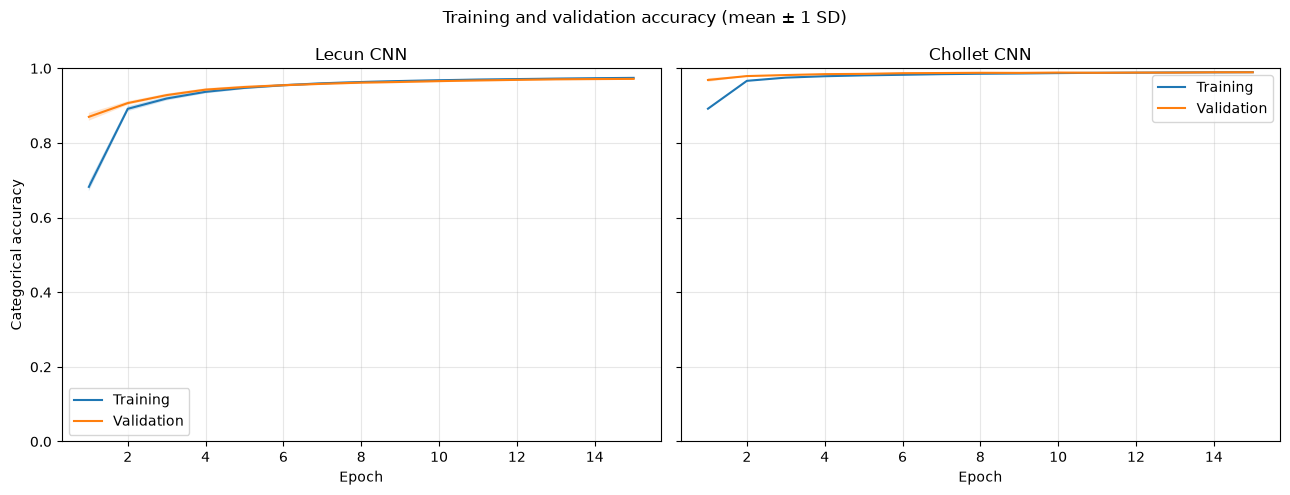

LEARNING CURVE FIGURES
------------------------------------------------------------
Accuracy    : C:\Users\User\Documents\Projects\mnist-lecun-cnn\notebooks\outputs\notebook_reproduction\figures\learning_curves_accuracy.png
File exists : True
Loss        : C:\Users\User\Documents\Projects\mnist-lecun-cnn\notebooks\outputs\notebook_reproduction\figures\learning_curves_loss.png
File exists : True


In [14]:
aggregated_histories = aggregate_histories(analysis_inputs)

figure_dir = notebook_output_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

learning_curve_paths = plot_learning_curve(
    aggregated_histories,
    figure_dir,
    show=True,
)

print("LEARNING CURVE FIGURES")
print("-" * 60)

for figure_name, figure_path in learning_curve_paths.items():
    print(f"{figure_name.capitalize():<12}: {figure_path.resolve()}")
    print(f"{'File exists':<12}: {figure_path.exists()}")